# FDTD with metals: dispersion, surface plasmons and SPR sensing

Metals and most real materials are dispersive: their permittivity depends
on frequency, and a pulse sees a different ε at each of its frequencies.
The FDTD handles this with one auxiliary equation per term of a
Drude/Lorentz model, advanced along with the fields. With metals the FDTD
can show what no ray or scalar wave model in pyoptics can: **surface
plasmon polaritons**, light bound to a metal surface, and their use in
**surface plasmon resonance (SPR) sensing**, the standard label-free
biosensor.

This notebook (continuing notebook [57](57_fdtd_basics.ipynb)):

1. dispersive media: the Drude model of gold, and a Lorentz fit of a glass,
2. a thin gold film over a whole band from one pulse, against `thin_films`,
3. a surface plasmon on gold: bound to the surface in the Hz polarization,
   absent in Ez; its effective index against the analytic dispersion
   relation,
4. the Kretschmann configuration: SPR curves and their shift with the
   refractive index of the sample (`thin_films`), and a Gaussian beam at and
   off resonance in the FDTD,
5. speed: NumPy and numba kernels.

Lengths are in µm, times in µm/c.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fdtd
from pyoptics.fdtd import plot as fplot
from pyoptics.thin_films import r_t_coeffs
from pyoptics.materials import abbe_dispersion

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
print("numba kernels available:", fdtd.numba_available)

numba kernels available: True


## 1. Dispersive media

A medium is $\varepsilon(\omega) = \varepsilon_\infty + i\sigma/\omega + \sum_k \chi_k(\omega)$
(time dependence $e^{-i\omega t}$), with

- Drude (free electrons): $\chi = -\omega_p^2/(\omega^2 + i\gamma\omega)$,
- Lorentz (bound charges): $\chi = \Delta\varepsilon\,\omega_0^2/(\omega_0^2 - \omega^2 - i\gamma\omega)$,
- Debye (relaxation): $\chi = \Delta\varepsilon/(1 - i\omega\tau)$.

Each term is a polarization density $P$ obeying an ordinary differential
equation driven by $E$ (for Lorentz $\ddot P + \gamma\dot P + \omega_0^2 P = \Delta\varepsilon\,\omega_0^2 E$),
discretized with central differences, so the scheme stays second order
(the Debye update is first order). In cells cut by a boundary, each
polarization is weighted with the filling fraction of its medium.

**Gold** above about 600 nm is described well by a Drude term on a
background $\varepsilon_\infty = 9.84$ (the d electrons), with
$\hbar\omega_p = 9.0$ eV and $\hbar\gamma = 0.067$ eV (a common fit;
below 600 nm the interband absorption of real gold sets in, which needs
additional Lorentz terms). `fdtd.omega_from_eV()` converts photon energies
to the normalized angular frequency for lengths in µm.

**Glass** from `materials.abbe_dispersion()` (N-BK7, $n_d$ = 1.5168,
$V_d$ = 64.17) is fitted by `Medium.fit()` with one Lorentz pole in the
UV (a one-term Sellmeier formula). The fit also takes tabulated $n + ik$
data, e.g. measured metal or semiconductor data.

Medium(eps=1, sigma=0, poles=[Lorentz(delta_eps=1.26462, omega_0=64.4538, gamma=4.73081e-17)])
max |Δn| of the fit: 2.3e-04


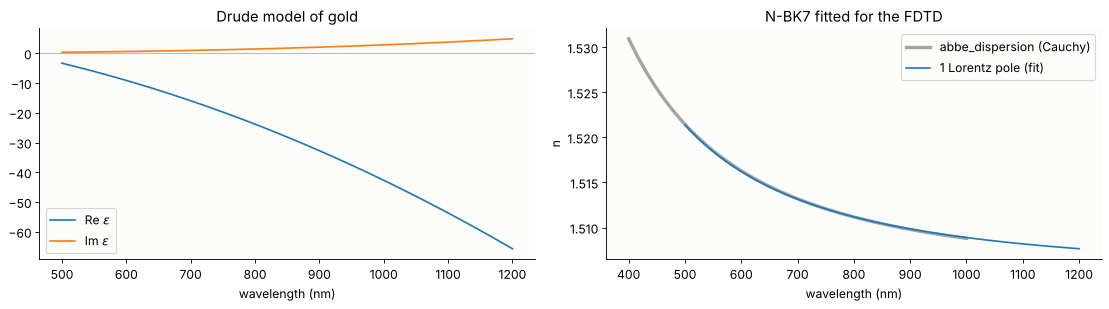

In [2]:
GOLD = fdtd.Medium(9.84, poles=[fdtd.Drude(fdtd.omega_from_eV(9.0), fdtd.omega_from_eV(0.067))])
wl = np.linspace(0.5, 1.2, 200)
eps_au = GOLD.complex_eps(wl)

wl_fit = np.linspace(0.4, 1.0, 40)
n_bk7 = abbe_dispersion(wl_fit*1e3, 1.5168, 64.17)
BK7 = fdtd.Medium.fit(wl_fit, n_bk7, n_lorentz=1)
print(BK7)
print("max |Δn| of the fit: %.1e" % np.abs(BK7.index(wl_fit) - n_bk7).max())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(wl*1e3, eps_au.real, label=r"Re $\varepsilon$")
ax1.plot(wl*1e3, eps_au.imag, label=r"Im $\varepsilon$")
ax1.axhline(0, color="0.6", lw=0.6)
ax1.set_xlabel("wavelength (nm)")
ax1.set_title("Drude model of gold")
ax1.legend()
ax2.plot(wl_fit*1e3, n_bk7, "k", lw=3, alpha=0.35, label="abbe_dispersion (Cauchy)")
ax2.plot(wl*1e3, BK7.index(wl).real, "C0", label="1 Lorentz pole (fit)")
ax2.set_xlabel("wavelength (nm)")
ax2.set_ylabel("n")
ax2.set_title("N-BK7 fitted for the FDTD")
ax2.legend()
plt.tight_layout()

## 2. A thin gold film, broadband, in 1D

A 50 nm gold film in air, hit by a pulse covering 500 to 1000 nm. The
skin depth of gold is about 25 nm; the cells must resolve it, which is
cheap in 1D. Reflectance, transmittance and absorptance follow from two
`Flux` monitors and a reference run, and are compared with `thin_films`
using the complex index of the same Drude model at each wavelength.

In [3]:
D_FILM = 0.05
wls = np.linspace(0.5, 1.0, 101)
pulse = fdtd.GaussianPulse(0.7, bandwidth=0.3)

def film_run(dx, structure):
    front, back = fdtd.Flux(-0.5, wls), fdtd.Flux(0.6, wls)
    sim = fdtd.Simulation(fdtd.Grid(3.0, dx), structure, [fdtd.PointSource(-1.0, pulse)],
                          [front, back], boundaries=fdtd.PML(int(0.3/dx)))
    sim.run(time=25)
    return front.flux(), back.flux()

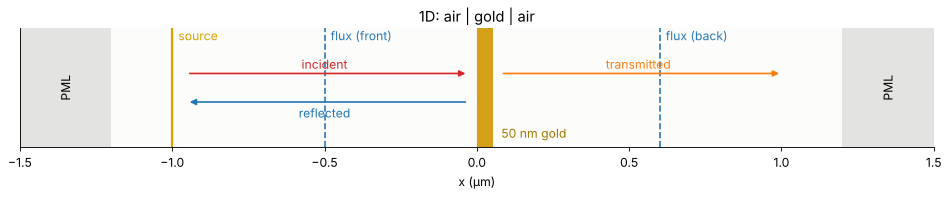

In [4]:
# the 1D set-up (the film to scale; the run without it gives the incident power)
fig, ax = plt.subplots(figsize=(12, 2.6))
for x0 in (-1.5, 1.2):
    ax.axvspan(x0, x0 + 0.3, color="0.5", alpha=0.2, lw=0)
ax.text(-1.35, 0.5, "PML", ha="center", rotation=90, va="center")
ax.text(1.35, 0.5, "PML", ha="center", rotation=90, va="center")
ax.axvspan(0, D_FILM, color="#d4a017")
ax.text(D_FILM + 0.03, 0.08, "50 nm gold", color="#a07800")
ax.axvline(-1.0, color=fplot.SOURCE_COLOR, lw=2)
ax.text(-0.98, 0.9, "source", color=fplot.SOURCE_COLOR)
for xm, name in ((-0.5, "flux (front)"), (0.6, "flux (back)")):
    ax.axvline(xm, color=fplot.MONITOR_COLOR, ls="--")
    ax.text(xm + 0.02, 0.9, name, color=fplot.MONITOR_COLOR)
arrow = dict(arrowstyle="-|>", lw=1.5)
ax.annotate("", (-0.03, 0.62), (-0.95, 0.62), arrowprops=dict(color="C3", **arrow))
ax.annotate("", (-0.95, 0.38), (-0.03, 0.38), arrowprops=dict(color="C0", **arrow))
ax.annotate("", (1.0, 0.62), (D_FILM + 0.03, 0.62), arrowprops=dict(color="C1", **arrow))
ax.text(-0.5, 0.66, "incident", color="C3", ha="center")
ax.text(-0.5, 0.25, "reflected", color="C0", ha="center")
ax.text(0.53, 0.66, "transmitted", color="C1", ha="center")
ax.set(xlim=(-1.5, 1.5), ylim=(0, 1), yticks=[], xlabel="x (µm)", title="1D: air | gold | air")
plt.tight_layout()

dx = 4 nm: max |ΔR| = 0.0001, max |ΔT| = 0.0001


dx = 2 nm: max |ΔR| = 0.0001, max |ΔT| = 0.0001


dx = 1 nm: max |ΔR| = 0.0000, max |ΔT| = 0.0000
10.4 s


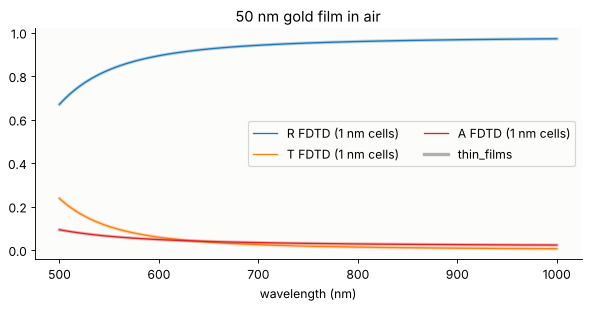

In [5]:
n_au = GOLD.index(wls)
exact = [r_t_coeffs(0, [n.real], [n.imag], [D_FILM], 1, 0, 1, 0, "s", w) for n, w in zip(n_au, wls)]
R_ex = np.array([abs(r)**2 for r, _ in exact])
T_ex = np.array([abs(t)**2 for _, t in exact])
t0 = time.perf_counter()
for dx in (0.004, 0.002, 0.001):
    inc, _ = film_run(dx, [])
    f, b = film_run(dx, [(fdtd.Slab(0, D_FILM), GOLD)])
    R, T = 1 - f/inc, b/inc
    print("dx = %.0f nm: max |ΔR| = %.4f, max |ΔT| = %.4f" % (dx*1e3, np.abs(R - R_ex).max(), np.abs(T - T_ex).max()))
print("%.1f s" % (time.perf_counter() - t0))

fig, ax = plt.subplots(figsize=(7.5, 4))
for y, ye, c, lab in ((R, R_ex, "C0", "R"), (T, T_ex, "C1", "T"), (1 - R - T, 1 - R_ex - T_ex, "C3", "A")):
    ax.plot(wls*1e3, ye, color=c, lw=3, alpha=0.3)
    ax.plot(wls*1e3, y, color=c, lw=1.2, label=lab + " FDTD (1 nm cells)")
ax.plot([], [], "k", lw=3, alpha=0.3, label="thin_films")
ax.set_xlabel("wavelength (nm)")
ax.set_title("50 nm gold film in air")
ax.legend(ncol=2)
plt.tight_layout()

## 3. A surface plasmon on gold

At the boundary between a metal (Re ε < 0) and a dielectric, Maxwell's
equations have a solution bound to the surface: a **surface plasmon
polariton** (SPP), a surface charge wave coupled to light. Its field decays
exponentially on both sides, and it exists only for **H parallel to the
surface and E in the plane of incidence**: the Hz mode here (TM or p in
the optics naming). Its wave number is

$$k_\text{SPP} = k_0\sqrt{\frac{\varepsilon_m\varepsilon_d}{\varepsilon_m + \varepsilon_d}},$$

slightly larger than in the dielectric alone, so light cannot couple to
it directly from the dielectric side (section 4 shows how to do it).

A point source (a magnetic line current for Hz, an electric one for Ez)
50 nm above a gold surface at λ = 800 nm, 10 nm cells, numba kernels:

In [6]:
WL_SPP = 0.8
def spp_setup(mode, dx=0.01):
    comp = "Hz" if mode == "Hz" else "Ez"
    dft = fdtd.DFTField(WL_SPP, components=[comp], region=((-1.5, 13.0), (-0.4, 2.4)))
    sim = fdtd.Simulation(fdtd.Grid((16.4, 3.4), dx, center=(5.7, 1.0)),
                          [(fdtd.Slab(-10, 0, axis=1), GOLD)],
                          [fdtd.PointSource((0, 0.05), fdtd.GaussianPulse(WL_SPP, 0.1), component=comp)],
                          [dft], mode=mode)
    return sim, dft


def spp_run(mode, dx=0.01):
    sim, dft = spp_setup(mode, dx)
    sim.run(time=35)
    return sim, dft

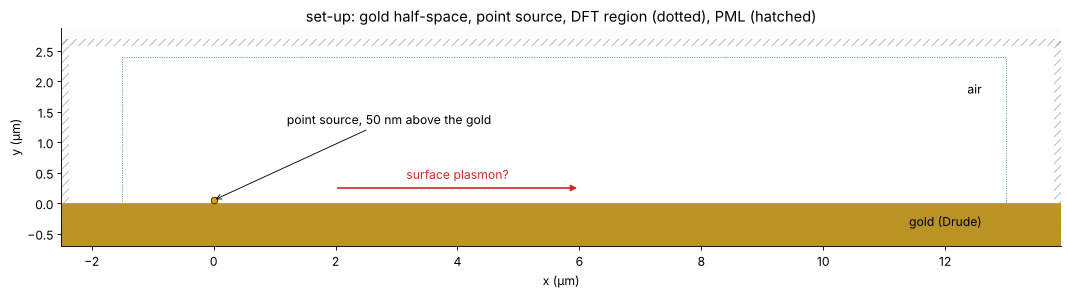

In [7]:
sim_s, _ = spp_setup("Hz")
fig, ax = plt.subplots(figsize=(15, 3.6))
fplot.plot_structure(sim_s, ax=ax)
ax.axhspan(-0.7, 0, color="#d4a017", alpha=0.8, lw=0)
ax.text(12.6, -0.3, "gold (Drude)", ha="right", va="center")
ax.text(12.6, 1.8, "air", ha="right")
ax.annotate("point source, 50 nm above the gold", (0, 0.05), (1.2, 1.3),
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.annotate("", (6.0, 0.25), (2.0, 0.25), arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.5))
ax.text(4.0, 0.4, "surface plasmon?", color="C3", ha="center")
ax.set(xlabel="x (µm)", ylabel="y (µm)",
       title="set-up: gold half-space, point source, DFT region (dotted), PML (hatched)")
plt.tight_layout()

two runs of 1640 × 340 cells: 33.0 s


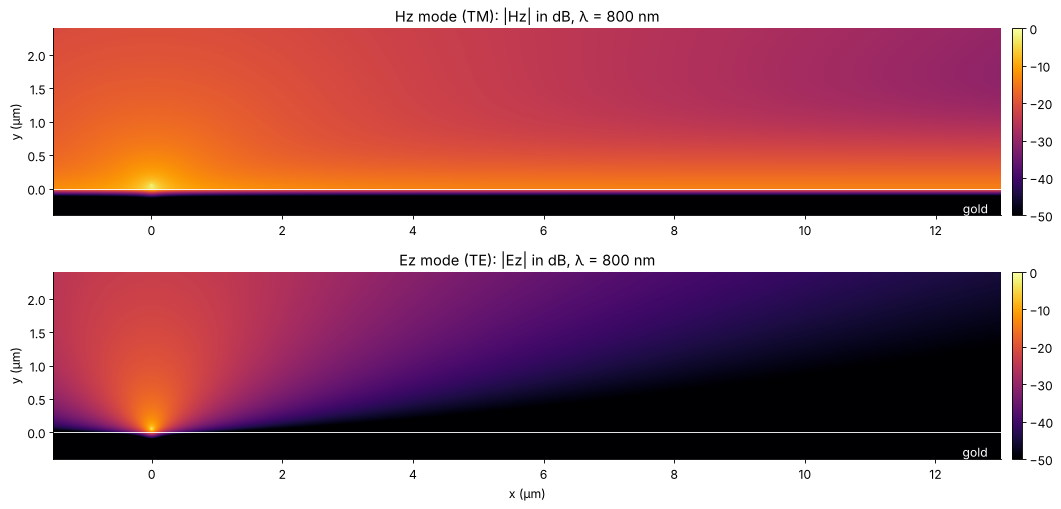

In [8]:
t0 = time.perf_counter()
sim_h, dft_h = spp_run("Hz")
sim_e, dft_e = spp_run("Ez")
print("two runs of %d × %d cells: %.1f s" % (*sim_h.grid.shape, time.perf_counter() - t0))

fig, axs = plt.subplots(2, 1, figsize=(15, 6.5))
for ax, d, comp, title in ((axs[0], dft_h, "Hz", "Hz mode (TM): |Hz|"),
                           (axs[1], dft_e, "Ez", "Ez mode (TE): |Ez|")):
    F = d.field(comp)[0]
    x, y = d.coords(comp)
    im = ax.imshow(20*np.log10(np.abs(F.T)/np.abs(F).max() + 1e-6), origin="lower",
                   extent=fplot._extent((x, y)), cmap="inferno", vmin=-50, vmax=0, aspect="auto")
    ax.axhline(0, color="w", lw=0.8)
    ax.text(12.8, -0.3, "gold", color="w", ha="right", va="center")
    ax.set_title(title + " in dB, λ = 800 nm")
    ax.set_ylabel("y (µm)")
    plt.colorbar(im, ax=ax, pad=0.01)
axs[1].set_xlabel("x (µm)")
plt.tight_layout()

In the Hz mode a bright ribbon runs along the surface over the whole 13 µm:
the plasmon, which loses only half its power over about 30 µm at 800 nm.
In the Ez mode the light is simply reflected by the metal; along the
surface it fades as a grazing wave.

**The effective index.** The phase of Hz along the surface gives
$k_\text{SPP}$. Close to the source the field also contains the light
radiated directly along the surface, which decays as $x^{-3/2}$ and shifts
a straight phase fit; far away, or with that term fitted along, the
plasmon's index agrees with the dispersion relation to about 1e-4:

In [9]:
from scipy.optimize import least_squares

eps_m = complex(GOLD.complex_eps(WL_SPP))
k0 = 2*np.pi/WL_SPP
n_spp = np.sqrt(eps_m/(eps_m + 1))
print("ε_gold(800 nm) = %.2f%+.2fi, analytic n_SPP = %.5f%+.5fi, propagation length %.0f µm"
      % (eps_m.real, eps_m.imag, n_spp.real, n_spp.imag, 1/(2*k0*n_spp.imag)))

x, y = dft_h.coords("Hz")
Fs = dft_h.field("Hz")[0][:, np.argmin(np.abs(y - 0.005))]   # first row above the gold
print("\nstraight phase fit over windows of 4 µm:")
for lo in (1, 3, 5, 7, 9):
    m = (x > lo) & (x < lo + 4)
    print("  x = %2d..%2d µm: n_eff = %.5f" % (lo, lo + 4, np.polyfit(x[m], np.unwrap(np.angle(Fs[m])), 1)[0]/k0))

m = (x > 2) & (x < 12.5)
xx, ff = x[m], Fs[m]
def residual(p):
    M = np.stack([np.exp(1j*k0*(p[0] + 1j*p[1])*xx), np.exp(1j*k0*xx)/xx**1.5], 1)
    c = np.linalg.lstsq(M, ff, rcond=None)[0]
    r = M @ c - ff
    return np.concatenate([r.real, r.imag])
fit = least_squares(residual, [1.0, 0.0])
print("\nplasmon plus direct wave, fitted together: n_eff = %.5f (analytic %.5f)" % (fit.x[0], n_spp.real))

ε_gold(800 nm) = -23.82+1.46i, analytic n_SPP = 1.02159+0.00136i, propagation length 47 µm

straight phase fit over windows of 4 µm:
  x =  1.. 5 µm: n_eff = 1.03026
  x =  3.. 7 µm: n_eff = 1.02572
  x =  5.. 9 µm: n_eff = 1.02363
  x =  7..11 µm: n_eff = 1.02241
  x =  9..13 µm: n_eff = 1.02164

plasmon plus direct wave, fitted together: n_eff = 1.02171 (analytic 1.02159)


## 4. Surface plasmon resonance sensing (Kretschmann)

To excite the plasmon, light must arrive with $k_x = k_\text{SPP}$. In the
**Kretschmann configuration** it comes from a glass prism through a thin
(≈ 50 nm) gold film: at the angle where $n_\text{glass}\,k_0\sin\theta = k_\text{SPP}$
on the far (sample) side, the evanescent field tunnels through the film,
excites the plasmon, and the reflected light drops sharply, only for
p polarization. The angle depends on the refractive index of the sample
touching the gold, which is how SPR sensors measure molecules binding to
the surface: a monolayer changes the index by about 1e-3.

First the exact curves from `thin_films` for glass (1.515) / 50 nm gold /
water at 633 nm:

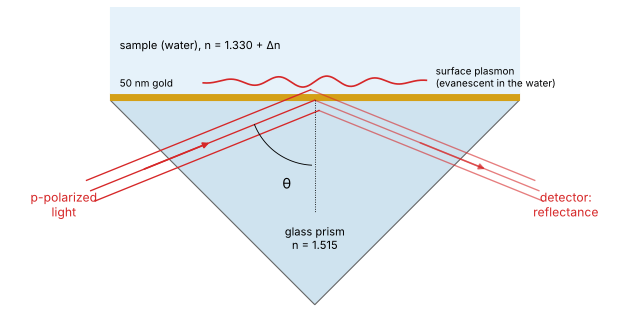

In [10]:
# the Kretschmann configuration (sketch, not to scale)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.fill([-2.2, 2.2, 0], [0, 0, -2.2], color="#cfe3ef", ec="0.4")           # prism
ax.fill_between([-2.2, 2.2], 0, 0.08, color="#d4a017")                         # gold film
ax.fill_between([-2.2, 2.2], 0.08, 1.0, color="#e6f2fa")                   # water
th = np.radians(68)
d = np.array([np.sin(th), np.cos(th)])
for s in (-0.12, 0.0, 0.12):                                              # p-polarized beam
    o = s*np.array([np.cos(th), -np.sin(th)])
    ax.plot(*np.transpose([o - 2.6*d, o]), color="C3", lw=1.2)
    ax.plot(*np.transpose([o, o + 2.6*np.array([d[0], -d[1]])]), color="C3", lw=1.2, alpha=0.6)
ax.annotate("", -1.2*d, -2.0*d, arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.5))
ax.annotate("", (2.0*d[0], -2.0*d[1]), (1.2*d[0], -1.2*d[1]),
            arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.5, alpha=0.6))
ax.plot([0, 0], [0, -1.2], "k:", lw=0.8)
a = np.linspace(np.pi/2 + 0.05, np.pi/2 + th, 30)
ax.plot(0.7*np.cos(a), -0.7*np.sin(a), "k", lw=0.8)
ax.text(-0.35, -0.95, "θ", fontsize=13)
xs = np.linspace(-1.2, 1.2, 200)
ax.plot(xs, 0.2 + 0.06*np.sin(12*xs)*np.exp(-xs**2), color="C3")
ax.text(1.3, 0.25, "surface plasmon\n(evanescent in the water)", fontsize=9, va="center")
ax.text(-2.1, 0.55, "sample (water), n = 1.330 + Δn", fontsize=10)
ax.text(-2.1, 0.12, "50 nm gold", fontsize=9, va="bottom")
ax.text(0, -1.6, "glass prism\nn = 1.515", ha="center", fontsize=10)
ax.text(-2.7, -1.25, "p-polarized\nlight", ha="center", color="C3")
ax.text(2.7, -1.25, "detector:\nreflectance", ha="center", color="C3")
ax.set(xlim=(-3.3, 3.3), ylim=(-2.3, 1.0), aspect="equal")
ax.axis("off")
plt.tight_layout()

sensitivity: 152 °/RIU


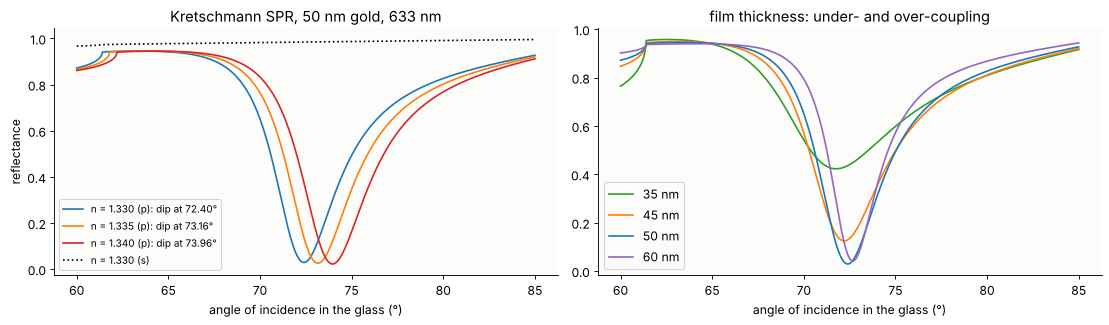

In [11]:
WL_SPR, N_GLASS, N_WATER = 0.633, 1.515, 1.330
n_gold = complex(GOLD.index(WL_SPR))
theta = np.deg2rad(np.linspace(60, 85, 2001))

def R_spr(n_sample, pol="p", th=theta, d=D_FILM):
    return np.array([abs(r_t_coeffs(t, [n_gold.real], [n_gold.imag], [d], N_GLASS, 0, n_sample, 0,
                                    pol, WL_SPR)[0])**2 for t in th])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
mins = []
for dn, c in ((0.0, "C0"), (0.005, "C1"), (0.010, "C3")):
    R = R_spr(N_WATER + dn)
    mins.append(np.rad2deg(theta[R.argmin()]))
    ax1.plot(np.rad2deg(theta), R, c, label="n = %.3f (p): dip at %.2f°" % (N_WATER + dn, mins[-1]))
ax1.plot(np.rad2deg(theta), R_spr(N_WATER, "s"), "k:", label="n = 1.330 (s)")
ax1.set_xlabel("angle of incidence in the glass (°)")
ax1.set_ylabel("reflectance")
ax1.legend(loc="lower left", fontsize=9)
ax1.set_title("Kretschmann SPR, 50 nm gold, 633 nm")
print("sensitivity: %.0f °/RIU" % ((mins[1] - mins[0])/0.005))

for d, c in ((0.035, "C2"), (0.045, "C1"), (0.050, "C0"), (0.060, "C4")):
    ax2.plot(np.rad2deg(theta), R_spr(N_WATER, d=d), c, label="%d nm" % (d*1e3))
ax2.set_xlabel("angle of incidence in the glass (°)")
ax2.set_title("film thickness: under- and over-coupling")
ax2.legend()
plt.tight_layout()

About 150° per refractive index unit: an index change of 1e-3 moves
the dip by about 0.15°, which a detector array resolves easily. The film
thickness sets the coupling: about 50 nm gives the deepest dip (critical
coupling, where radiative and absorption losses of the plasmon are equal);
thinner films over-couple and broaden it, thicker ones under-couple.

**In the FDTD.** A Gaussian beam (waist 2.5 µm, p polarized, the Hz mode)
from a tilted line source in the glass hits the film, once at the SPR angle
and once 7° off. Two `Flux` lines in the glass measure the incident and
the reflected beam. A beam is a bundle of plane waves with an angular
spread of about 1.7° here, so the reference is `thin_films` averaged over
the beam's angular spectrum. Cells of 10 nm (5 across the film); each run
takes about half a minute with the numba kernels.

In [12]:
W_BEAM = 2.5

def kretschmann_setup(theta_deg, dx=0.01):
    a = np.deg2rad(90 - theta_deg)     # beam direction from the x axis
    x_src = -5.0
    y_src = x_src*np.tan(a)            # the beam axis hits the film at x = 0
    src = fdtd.LineSource(x_src, fdtd.GaussianPulse(WL_SPR, 0.08), axis=0, extent=(-8.5, -0.05),
                          transverse=lambda s: np.exp(-((s - y_src)*np.cos(a)/W_BEAM)**2),
                          angle=a, n=N_GLASS, center=y_src)
    inc = fdtd.Flux(-4.0, [WL_SPR], axis=0, extent=(-8.5, -0.1))
    refl = fdtd.Flux(6.0, [WL_SPR], axis=0, extent=(-8.5, -0.1))
    dft = fdtd.DFTField(WL_SPR, components=["Hz"], stride=2)
    sim = fdtd.Simulation(fdtd.Grid((13.0, 10.5), dx, center=(1.0, -3.75)),
                          [(fdtd.Slab(-10, 0, axis=1), fdtd.Medium(N_GLASS**2)),
                           (fdtd.Slab(0, D_FILM, axis=1), GOLD)],
                          [src], [inc, refl, dft], mode="Hz", background=fdtd.Medium(N_WATER**2))
    return sim, inc, refl, dft


def kretschmann(theta_deg, dx=0.01):
    sim, inc, refl, dft = kretschmann_setup(theta_deg, dx)
    sim.run(time=40)
    return sim, refl.flux()[0]/inc.flux()[0], dft

def R_beam(theta_deg):
    th = np.deg2rad(theta_deg + np.linspace(-6, 6, 601))
    weights = np.exp(-(2*np.pi/WL_SPR*N_GLASS*(th - np.deg2rad(theta_deg))*W_BEAM)**2/2)
    return np.sum(weights*R_spr(N_WATER, th=th))/np.sum(weights)

theta_spr = mins[0]

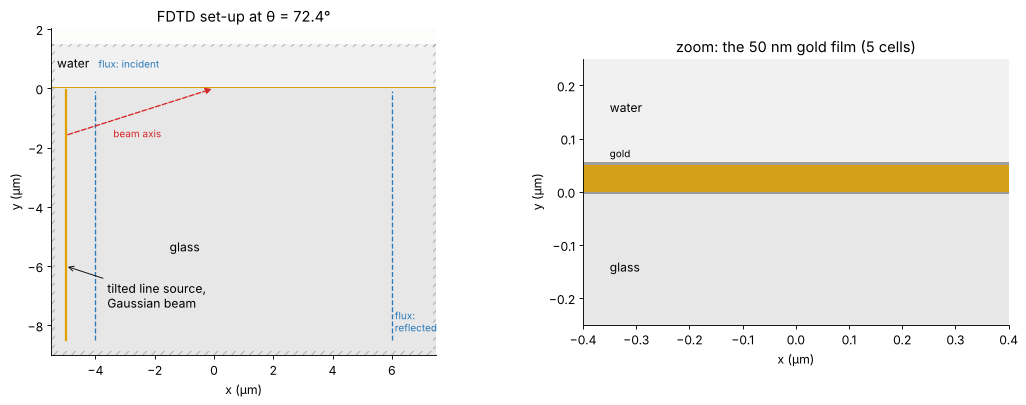

In [13]:
sim_k = kretschmann_setup(theta_spr)[0]
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
for ax in axs:
    fplot.plot_structure(sim_k, ax=ax)
    ax.axhspan(0, D_FILM, color="#d4a017", lw=0)
    ax.set(xlabel="x (µm)", ylabel="y (µm)")
axs[0].text(-5.3, 0.7, "water")
axs[0].text(-1.5, -5.5, "glass")
axs[0].annotate("tilted line source,\nGaussian beam", (-5.0, -6.0), (-3.6, -7.4),
                arrowprops=dict(arrowstyle="->", lw=0.8))
axs[0].annotate("", (0, 0), (-5.0, -5.0*np.tan(np.deg2rad(90 - theta_spr))),
                arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.2, ls="--"))
axs[0].text(-3.4, -1.65, "beam axis", color="C3", fontsize=9)
axs[0].text(-3.9, 0.7, "flux: incident", color=fplot.MONITOR_COLOR, fontsize=9)
axs[0].text(6.1, -8.2, "flux:\nreflected", color=fplot.MONITOR_COLOR, fontsize=9)
axs[0].set_title("FDTD set-up at θ = %.1f°" % theta_spr)
axs[1].set(xlim=(-0.4, 0.4), ylim=(-0.25, 0.25), title="zoom: the 50 nm gold film (5 cells)")
axs[1].text(-0.35, 0.15, "water")
axs[1].text(-0.35, 0.065, "gold", fontsize=9)
axs[1].text(-0.35, -0.15, "glass")
plt.tight_layout()

In [14]:
results = {}
t0 = time.perf_counter()
for th in (theta_spr, theta_spr - 7):
    results[th] = kretschmann(th)
    print("θ = %.1f°: R FDTD = %.3f, thin_films (beam) = %.3f, (plane wave) = %.3f"
          % (th, results[th][1], R_beam(th), R_spr(N_WATER, th=np.deg2rad([th]))[0]))
print("%.0f s" % (time.perf_counter() - t0))

θ = 72.4°: R FDTD = 0.276, thin_films (beam) = 0.259, (plane wave) = 0.029


θ = 65.4°: R FDTD = 0.907, thin_films (beam) = 0.930, (plane wave) = 0.940
113 s


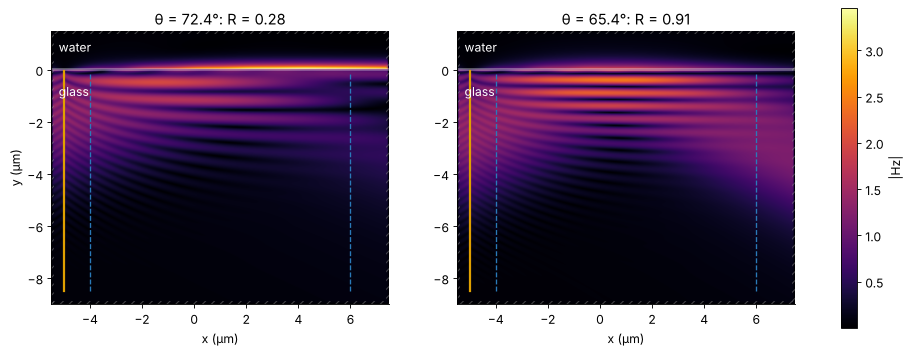

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
vmax = max(np.abs(r[2].field("Hz")[0]).max() for r in results.values())
for ax, (th, (sim, R, dft)) in zip(axs, results.items()):
    F = dft.field("Hz")[0]
    x, y = dft.coords("Hz")
    im = ax.imshow(np.abs(F).T, origin="lower", extent=fplot._extent((x, y)), cmap="inferno",
                   vmax=vmax, aspect="equal")
    fplot._structure_outline(ax, sim, color="w", lw=0.5)
    fplot._overlays(ax, sim, show_sources=True, show_monitors=True)
    ax.set_xlim(x[0], x[-1])
    ax.set_ylim(y[0], y[-1])
    ax.set_title("θ = %.1f°: R = %.2f" % (th, R))
    ax.set_xlabel("x (µm)")
    ax.text(-5.2, 0.7, "water", color="w")
    ax.text(-5.2, -1.0, "glass", color="w")
axs[0].set_ylabel("y (µm)")
plt.colorbar(im, ax=axs, shrink=0.8, label="|Hz|")

At the SPR angle (left) the reflected beam is almost gone: the energy goes
into the plasmon, which shows up as the strong field on the water side of
the film. It runs along the surface beyond the beam and leaks back into the
glass as it goes, which shifts and broadens the faint reflected beam
(Goos-Hänchen shift, as in notebook [13](13_stack_transfer_functions.ipynb)).
Off resonance (right) the beam is totally reflected, with only a weak
evanescent field above the gold.

The FDTD reflectances agree with the beam-averaged thin film values to
within a few percent at 10 nm cells, which is about as good as five cells
across a strongly absorbing film allow. Metal boundaries in the Hz mode
are the hard case of the FDTD: E crosses them, and ε changes sign across
them. Convergence there is only first order with plain filling-fraction
averaging (`test_fdtd.py` checks a Drude cylinder, which converges with
second order in the Ez mode).

## 5. Speed: NumPy and numba kernels

The NumPy kernels are the reference implementation. With numba installed
(`pip install pyoptics[fast]`), `Simulation(backend="auto")` uses compiled
kernels that update all components in one parallel loop, including the
PML and the dispersive currents. The results are identical to the last
bit:

In [16]:
def timing(backend, dtype=np.float64, n=600, steps=100):
    sim = fdtd.Simulation(fdtd.Grid((n/100, n/100), 0.01), [(fdtd.Circle((0, 0), 1.0), GOLD)],
                          [fdtd.PointSource((-2, 0), fdtd.GaussianPulse(0.8))], mode="Hz",
                          backend=backend, dtype=dtype)
    sim.run(steps=5)    # compile / warm up
    t0 = time.perf_counter()
    sim.run(steps=steps)
    return steps*n*n/(time.perf_counter() - t0)/1e6, sim

print("grid 600 × 600 with a gold disc and a 12 cell PML, Hz mode")
rates = {}
for be in ("numpy", "numba"):
    for dt in (np.float64, np.float32):
        rate, s = timing(be, dt)
        rates[(be, dt)] = s
        print("  %-6s %-8s %6.0f million cell updates per second" % (be, np.dtype(dt).name, rate))
a, b = rates[("numpy", np.float64)], rates[("numba", np.float64)]
print("largest difference numpy/numba (float64):",
      max(np.abs(a.fields[c] - b.fields[c]).max() for c in a.components))

grid 600 × 600 with a gold disc and a 12 cell PML, Hz mode


  numpy  float64      25 million cell updates per second


  numpy  float32      51 million cell updates per second


  numba  float64     259 million cell updates per second


  numba  float32     336 million cell updates per second
largest difference numpy/numba (float64): 0.0


On a 4-core machine the compiled kernels are about ten times faster; they
use all cores. The runs of sections 3 and 4 (up to 2 million cells and
6000 steps) take tens of seconds instead of several minutes.

## Summary

- Drude, Lorentz and Debye media enter through auxiliary equations; thin
  dispersive films agree with `thin_films` over a whole band from one pulse.
- A gold surface carries a surface plasmon in the Hz (TM) polarization
  only; its effective index matches the dispersion relation to about 1e-4.
- In the Kretschmann configuration a beam at the SPR angle is absorbed
  into the plasmon, and the angle shifts by about 0.1° per 1e-3 change of
  the sample's refractive index.
- Next: waveguide modes, mode sources and S-parameters for directional
  couplers and ring resonators, where the same index sensitivity drives
  ring resonator sensors.